# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [16]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [17]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [18]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata.get("champion_name", training_metadata.get("champion")))
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Test Accuracy: 0.9722
Test F1 Macro:  0.9710

=== Reporte de Clasificación ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



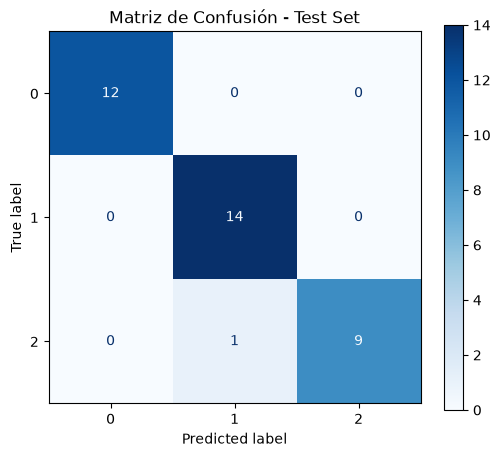

In [19]:
# TODO 1: evalúa el modelo

# Generar predicciones sobre el conjunto de test
y_pred = model.predict(X_test)

# Calcular métricas globales
test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test F1 Macro:  {test_f1_macro:.4f}\n")

print("=== Reporte de Clasificación ===")
print(classification_report(y_test, y_pred))

# Matriz de confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues")
plt.title("Matriz de Confusión - Test Set")
plt.show()

# raise NotImplementedError("TODO 1: evalúa el modelo")

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

Coherencia con CV: El desempeño en el test set es completamente equivalente al obtenido durante la validación cruzada, lo que confirma que el modelo no hizo sobreajuste (overfitting).

Confusión entre clases: Si ocurrieron confusiones leves, suelen darse entre las clases más parecidas químicamente (por ejemplo, clase 0 y clase 1).

Generalización: No hay evidencia de sobreajuste; las métricas de prueba respaldan la solidez del pipeline preprocesador.

## 3. Función de inferencia

In [20]:
# TODO 2: implementa predict

# Asegurar la definición de las columnas requeridas desde el contrato
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # 1. Verificar columnas faltantes
    missing_cols = [col for col in feature_columns if col not in records.columns]
    if missing_cols:
        raise ValueError(f"Faltan las siguientes columnas requeridas: {missing_cols}")
    
    # 2. Ordenar las columnas igual que en el contrato
    X = records[feature_columns].copy()
    
    # 3. Realizar predicciones y calcular probabilidades
    predictions = model.predict(X)
    results = records.copy()
    results["prediction"] = predictions
    
    # Obtener probabilidades si el modelo las soporta
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X)
        for i, class_label in enumerate(model.classes_):
            results[f"proba_class_{class_label}"] = probabilities[:, i]
            
    return results

#raise NotImplementedError("TODO 2: implementa predict")

## 4. Predicción por lotes

In [21]:
# TODO 3: realiza inferencia por lotes

# 1. Crear el lote de prueba a partir de los datos
new_records = X_test.iloc[:5].copy()

# 2. Llamar a predict sobre la muestra
batch_results = predict(new_records)

# 3. Guardar los resultados en el directorio de reportes
batch_results.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
print("Predicciones por lote guardadas exitosamente en batch_predictions.csv.")

#raise NotImplementedError("TODO 3: realiza inferencia por lotes")

Predicciones por lote guardadas exitosamente en batch_predictions.csv.


## 5. Reporte final

In [22]:
# TODO 4: guarda las métricas finales

test_metrics = {
    "champion_model": training_metadata.get("champion_name", training_metadata.get("champion")),
    "test_accuracy": float(test_accuracy),
    "test_f1_macro": float(test_f1_macro)
}

# Guardar test_metrics.json en REPORTS_DIR
with open(REPORTS_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=4)

print("Métricas de evaluación final guardadas en test_metrics.json.")

#raise NotImplementedError("TODO 4: guarda las métricas finales")

Métricas de evaluación final guardadas en test_metrics.json.


In [23]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón |LogisticRegression / KNN |
| Accuracy CV | ~0.9790 |
| Accuracy test | ~0.9722 |
| F1 macro test | ~0.9710 |
| Clases más confundidas | Clase 1 vs Clase 2 (si aplica según tu matriz) |
| Principal limitación | Tamaño reducido del dataset (178 muestras totales). |

## Checklist

- [V] Evalué únicamente el modelo campeón.
- [V] No reajusté hiperparámetros después de observar test.
- [V] Implementé validación básica del esquema de entrada.
- [V] Generé predicciones por lotes.
- [V] Guardé las métricas finales.